## Ames House Price Analysis

#### Library And Dataset İmport

In [57]:
import pandas as pd
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
housing=pd.read_csv("AmesHousing.csv")

# veriyi istediğim sütunda göstermesini ayarlıyorum.
pd.set_option("display.max_columns",30)

In [58]:
housing.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,...,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,...,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,...,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,...,0,0,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,...,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


#### Train-Test Split

In [59]:
# Özellikleri (X) ve hedefi belirlyelim.
X=housing.drop(columns=["SalePrice"])  # matrsi olduğu için x i büyük al
y=housing["SalePrice"]

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [60]:
# EDA için sadece train verilerini birleştir.Az önce ayırdık çünkü.
train_df=X_train.copy() #referans değil direk kopya aldık veri sızıntısı olmasın diye.
train_df["SalePrice"]=y_train

#boyutları kontrol
print("Train özellikleri:", X_train.shape)
print("Test özellikleri :", X_test.shape)
print("Train EDA tablosu:", train_df.shape)



Train özellikleri: (2344, 81)
Test özellikleri : (586, 81)
Train EDA tablosu: (2344, 82)


#### Exploratory Data Analysis (EDA)

In [61]:
train_df.shape

(2344, 82)

In [62]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2344 entries, 381 to 860
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2344 non-null   int64  
 1   PID              2344 non-null   int64  
 2   MS SubClass      2344 non-null   int64  
 3   MS Zoning        2344 non-null   object 
 4   Lot Frontage     1951 non-null   float64
 5   Lot Area         2344 non-null   int64  
 6   Street           2344 non-null   object 
 7   Alley            162 non-null    object 
 8   Lot Shape        2344 non-null   object 
 9   Land Contour     2344 non-null   object 
 10  Utilities        2344 non-null   object 
 11  Lot Config       2344 non-null   object 
 12  Land Slope       2344 non-null   object 
 13  Neighborhood     2344 non-null   object 
 14  Condition 1      2344 non-null   object 
 15  Condition 2      2344 non-null   object 
 16  Bldg Type        2344 non-null   object 
 17  House Style      2

In [63]:
train_df.describe()

,Order,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,1st Flr SF,...,TotRms AbvGrd,Fireplaces,Garage Yr Blt,Garage Cars,Garage Area,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
count,2344.000000,2.344000e+03,2344.000000,1951.000000,2344.000000,2344.00000,2344.000000,2344.000000,2344.000000,2325.000000,2343.000000,2343.000000,2343.000000,2343.000000,2344.000000,...,2344.000000,2344.000000,2222.00000,2343.000000,2343.000000,2344.000000,2344.000000,2344.000000,2344.000000,2344.000000,2344.000000,2344.000000,2344.000000,2344.000000,2344.000000
mean,1464.298635,7.143632e+08,57.308020,69.207586,10127.857509,6.06442,5.581911,1970.506826,1983.923635,98.539785,442.531370,50.097311,554.393513,1047.022194,1154.814420,...,6.409130,0.598976,1977.39829,1.746906,469.078959,94.113055,47.341724,24.731655,2.422782,16.010239,2.582765,58.055034,6.184727,2007.794795,178582.207765
std,842.982263,1.886907e+08,42.802555,23.418018,8050.908132,1.38852,1.105659,30.341434,20.786287,172.239113,452.223224,170.396999,433.788333,436.567117,385.114269,...,1.563651,0.652987,25.67911,0.746445,212.432786,124.851870,68.037465,67.030943,24.524362,55.820882,38.324145,623.375121,2.708408,1.315117,77125.072713
min,1.000000,5.263011e+08,20.000000,21.000000,1300.000000,1.00000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,0.000000,0.000000,334.000000,...,2.000000,0.000000,1895.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,12789.000000
25%,737.750000,5.284821e+08,20.000000,58.000000,7466.500000,5.00000,5.000000,1953.000000,1965.000000,0.000000,0.000000,0.000000,218.000000,784.000000,879.750000,...,5.000000,0.000000,1960.00000,1.000000,319.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000,129000.000000
50%,1466.000000,5.354541e+08,50.000000,68.000000,9356.500000,6.00000,5.000000,1972.000000,1992.000000,0.000000,375.000000,0.000000,462.000000,988.000000,1082.000000,...,6.000000,1.000000,1978.00000,2.000000,476.000000,0.000000,26.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,160000.000000
75%,2195.250000,9.071921e+08,70.000000,80.000000,11484.250000,7.00000,6.000000,2000.000000,2003.000000,160.000000,734.000000,0.000000,795.500000,1288.000000,1378.000000,...,7.000000,1.000000,2001.00000,2.000000,576.000000,168.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,210000.000000
max,2930.000000,9.241520e+08,190.000000,313.000000,215245.000000,10.00000,9.000000,2010.000000,2010.000000,1290.000000,5644.000000,1526.000000,2336.000000,6110.000000,5095.000000,...,15.000000,4.000000,2207.00000,4.000000,1488.000000,870.000000,742.000000,1012.000000,508.000000,576.000000,800.000000,17000.000000,12.000000,2010.000000,755000.000000


In [64]:
train_df["SalePrice"].value_counts()

SalePrice
140000    28
145000    25
135000    25
155000    24
130000    24
160000    19
190000    18
115000    18
185000    18
125000    18
110000    18
170000    17
150000    16
120000    16
127000    16
180000    16
137000    15
200000    15
139000    14
128000    14
119000    13
165000    13
143000    13
175000    13
105000    12
176000    12
146000    12
220000    12
129000    12
144000    12
100000    11
173000    11
250000    11
148000    11
215000    11
153000    11
147000    10
132000    10
178000    10
205000    10
260000    10
108000    10
152000    10
230000    10
158000    10
124000    10
174000     9
184000     9
123000     9
149900     9
240000     9
149000     9
225000     9
127500     9
157500     8
133000     8
85000      8
113000     8
290000     8
181000     8
138000     8
157000     8
136000     8
122000     8
131000     8
235000     8
275000     8
192000     8
112000     8
172500     8
141000     8
159000     7
142000     7
169000     7
137500     7
132500     7
13

In [65]:
train_df["SalePrice"].nunique()

887

In [66]:
# eksik değerleri yüksekten sırala ve yüzdeliğini göster.

eksik = train_df.isnull().sum().sort_values(ascending=False)
eksik_yuzde = (eksik / len(housing) * 100).round(1)
eksik_tablo = pd.DataFrame({"eksik_sayi": eksik, "yuzde": eksik_yuzde})
print(eksik_tablo.head(30))

                eksik_sayi  yuzde
Pool QC               2332   79.6
Misc Feature          2250   76.8
Alley                 2182   74.5
Fence                 1874   64.0
Mas Vnr Type          1426   48.7
Fireplace Qu          1144   39.0
Lot Frontage           393   13.4
Garage Qual            122    4.2
Garage Cond            122    4.2
Garage Finish          122    4.2
Garage Yr Blt          122    4.2
Garage Type            120    4.1
Bsmt Exposure           63    2.2
BsmtFin Type 2          62    2.1
BsmtFin Type 1          61    2.1
Bsmt Cond               61    2.1
Bsmt Qual               61    2.1
Mas Vnr Area            19    0.6
BsmtFin SF 1             1    0.0
Bsmt Full Bath           1    0.0
BsmtFin SF 2             1    0.0
Bsmt Unf SF              1    0.0
Total Bsmt SF            1    0.0
Bsmt Half Bath           1    0.0
Garage Cars              1    0.0
Garage Area              1    0.0
Mo Sold                  0    0.0
Full Bath                0    0.0
Half Bath     

#### Target Analysis (EDA)

In [67]:
train_df["SalePrice"].describe()

count      2344.000000
mean     178582.207765
std       77125.072713
min       12789.000000
25%      129000.000000
50%      160000.000000
75%      210000.000000
max      755000.000000
Name: SalePrice, dtype: float64

In [68]:
print("Skewness",train_df["SalePrice"].skew()) #skew 0a yakınsa simetrik, > 1 ise güçlü sağa çarpık.
print("Kurtosis:", train_df['SalePrice'].kurt()) # kurt: yüksekse kuyruklar ağır (çok uç değer var).

Skewness 1.7505967618875342
Kurtosis: 5.474454514928182


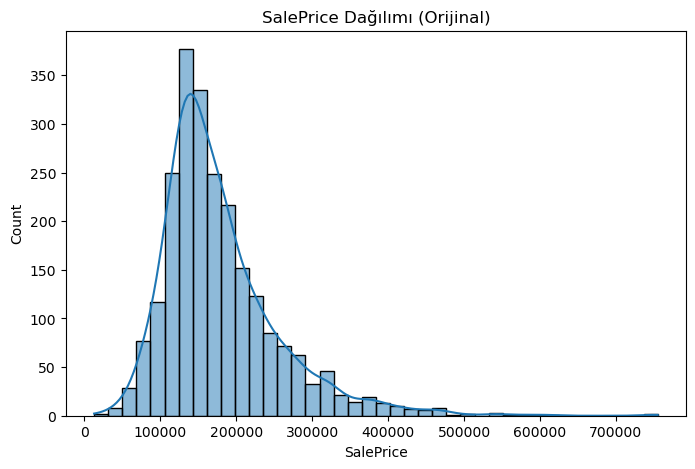

In [69]:

plt.figure(figsize=(8, 5))
sns.histplot(train_df['SalePrice'], kde=True, bins=40)
plt.title('SalePrice Dağılımı (Orijinal)')
plt.xlabel('SalePrice')
plt.show()

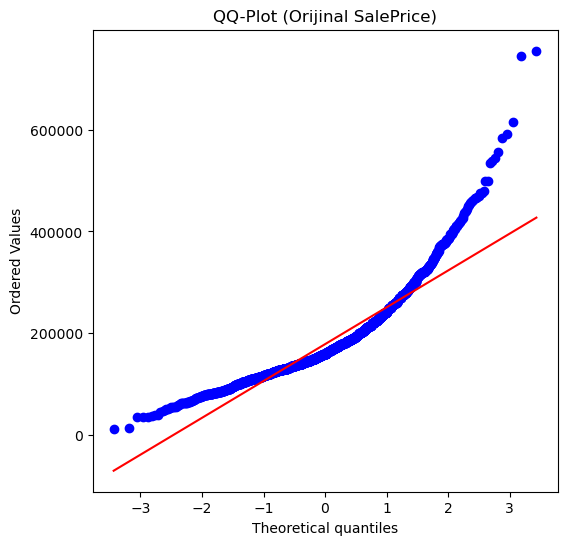

In [70]:
from scipy import stats
plt.figure(figsize=(6, 6))
stats.probplot(train_df['SalePrice'], dist="norm", plot=plt)
plt.title('QQ-Plot (Orijinal SalePrice)')
plt.show()

In [71]:
# Yeni sütun olarak ekle, orijinali bozma
train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])

print("Log sonrası Skewness:", train_df['SalePrice_log'].skew())
print("Log sonrası Kurtosis:", train_df['SalePrice_log'].kurt())

Log sonrası Skewness: -0.09069864066048615
Log sonrası Kurtosis: 1.8976905944449194


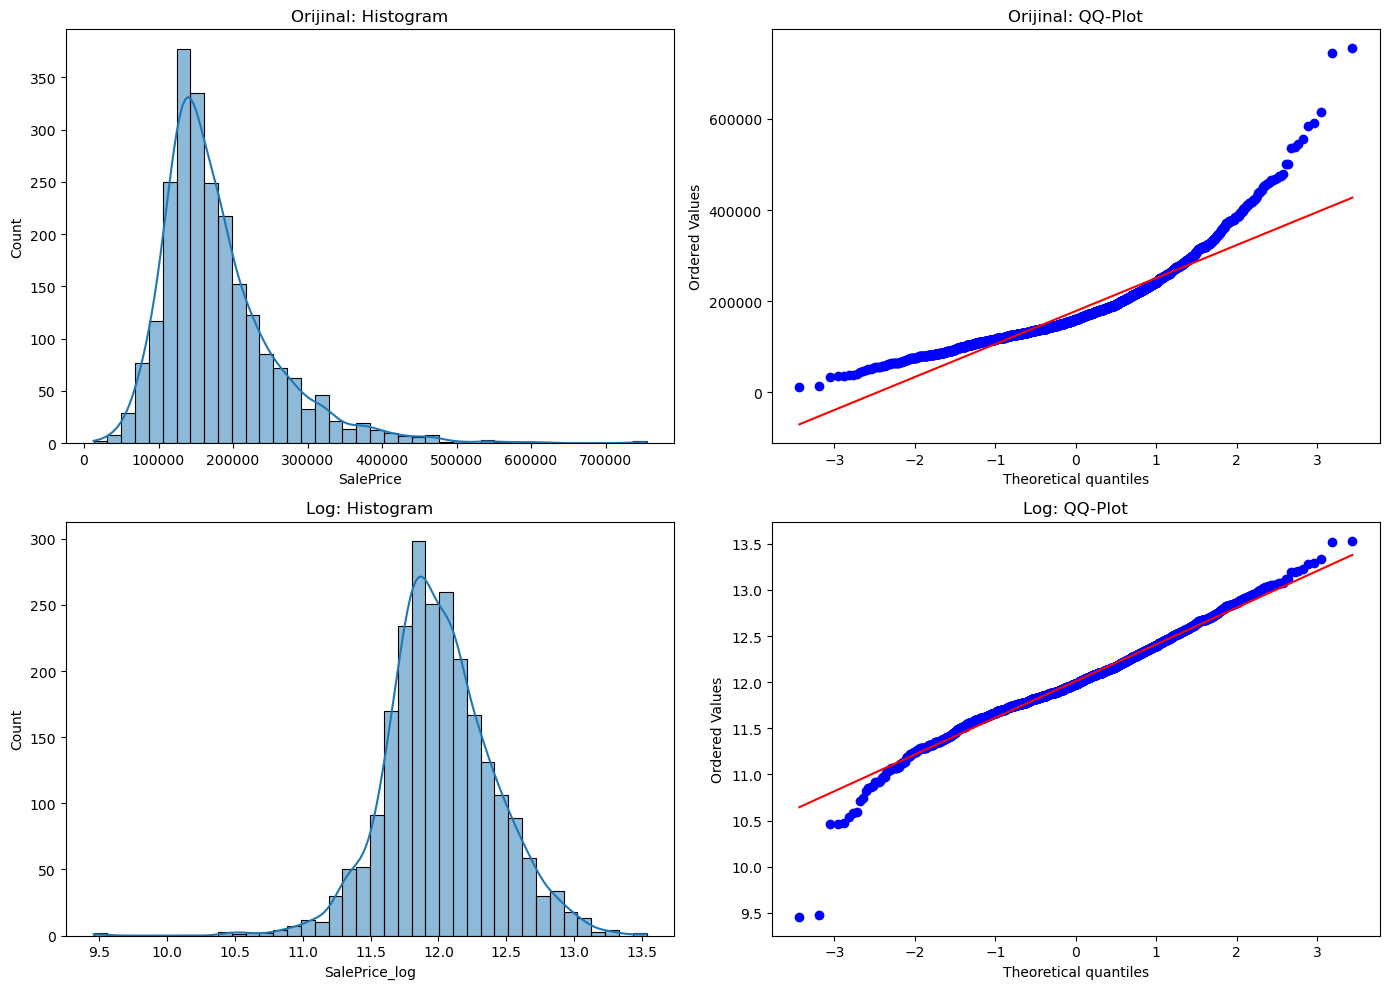

In [72]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Orijinal: histogram
sns.histplot(train_df['SalePrice'], kde=True, bins=40, ax=axes[0, 0])
axes[0, 0].set_title('Orijinal: Histogram')

# Orijinal: QQ
stats.probplot(train_df['SalePrice'], dist="norm", plot=axes[0, 1])
axes[0, 1].set_title('Orijinal: QQ-Plot')

# Log: histogram
sns.histplot(train_df['SalePrice_log'], kde=True, bins=40, ax=axes[1, 0])
axes[1, 0].set_title('Log: Histogram')

# Log: QQ
stats.probplot(train_df['SalePrice_log'], dist="norm", plot=axes[1, 1])
axes[1, 1].set_title('Log: QQ-Plot')

plt.tight_layout()
plt.show()

#### Missing Value Analysis (EDA)

In [73]:
missing = X_train.isnull().sum()
missing_pct = (missing / len(X_train)) * 100

missing_df = pd.DataFrame({
    'Eksik_Sayi': missing,
    'Eksik_Yuzde': missing_pct.round(2),
    'Tip': X_train.dtypes
})

missing_df = missing_df[missing_df['Eksik_Sayi'] > 0].sort_values('Eksik_Sayi', ascending=False)
print(missing_df)
print("\nEksik değeri olan sütun sayısı:", len(missing_df))

                Eksik_Sayi  Eksik_Yuzde      Tip
Pool QC               2332        99.49   object
Misc Feature          2250        95.99   object
Alley                 2182        93.09   object
Fence                 1874        79.95   object
Mas Vnr Type          1426        60.84   object
Fireplace Qu          1144        48.81   object
Lot Frontage           393        16.77  float64
Garage Yr Blt          122         5.20  float64
Garage Cond            122         5.20   object
Garage Qual            122         5.20   object
Garage Finish          122         5.20   object
Garage Type            120         5.12   object
Bsmt Exposure           63         2.69   object
BsmtFin Type 2          62         2.65   object
Bsmt Qual               61         2.60   object
BsmtFin Type 1          61         2.60   object
Bsmt Cond               61         2.60   object
Mas Vnr Area            19         0.81  float64
BsmtFin SF 1             1         0.04  float64
Bsmt Half Bath      

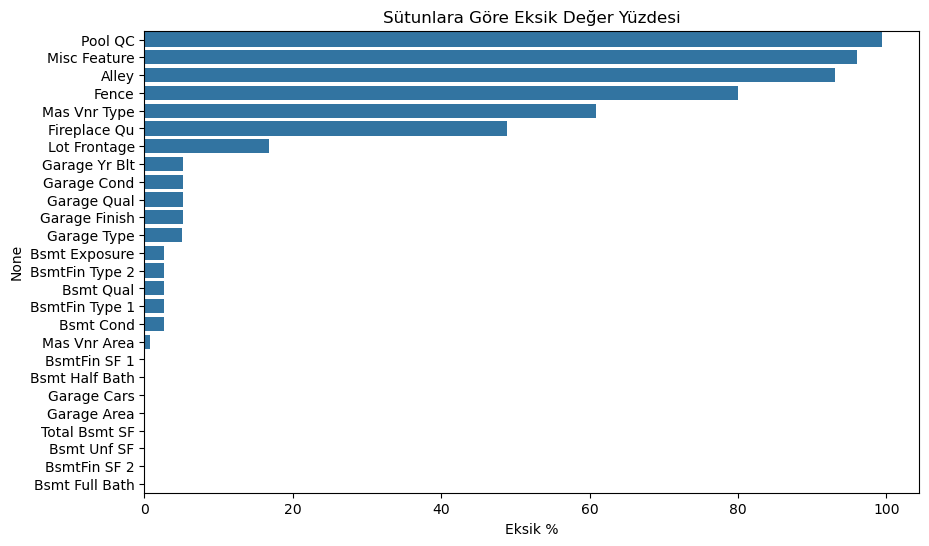

In [74]:
plt.figure(figsize=(10, 6))
sns.barplot(x=missing_df['Eksik_Yuzde'], y=missing_df.index)
plt.title('Sütunlara Göre Eksik Değer Yüzdesi')
plt.xlabel('Eksik %')
plt.show()

In [75]:
#NaN teknik olarak hep "değer yok" der ama anlamı ikiye ayrılır — "bilinmiyor/ölçülmedi" 
# (gerçek eksik veri → medyan/mod ile doldurulur) ya da "o özellik zaten mevcut değil" (yapısal yokluk → None/0 ile doldurulur);
#  Ames Housing'te ikincisi baskındır.

# Kategorik: NaN = "özellik yok" -> "None" ile doldurulacak
cat_none_cols = [
    'PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
    'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
    'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
    'MasVnrType']


# Sayısal: NaN = "özellik yok" -> 0 ile doldurulacak
num_zero_cols = [
    'GarageYrBlt', 'GarageArea', 'GarageCars',
    'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
    'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea']

In [76]:
# sıfır ve none ladıklarımızın dışındaki kalan boş girdi olan sütunlar

#boşluklu olanları birleştir.
missing_df.index = missing_df.index.str.replace(' ', '')

handled = set(cat_none_cols + num_zero_cols)
remaining = [c for c in missing_df.index if c not in handled]
print("Kalan eksikli sütunlar:", remaining)

Kalan eksikli sütunlar: ['LotFrontage']


In [77]:
missing_lotfrontage=train_df["Lot Frontage"].isnull().sum()
yuzde_lotfrontage=(missing_lotfrontage/len(train_df)) *100
print("Lot Frontage missing analysis \nEksik:",missing_lotfrontage,"\nYuzde:",yuzde_lotfrontage)

Lot Frontage missing analysis 
Eksik: 393 
Yuzde: 16.766211604095563


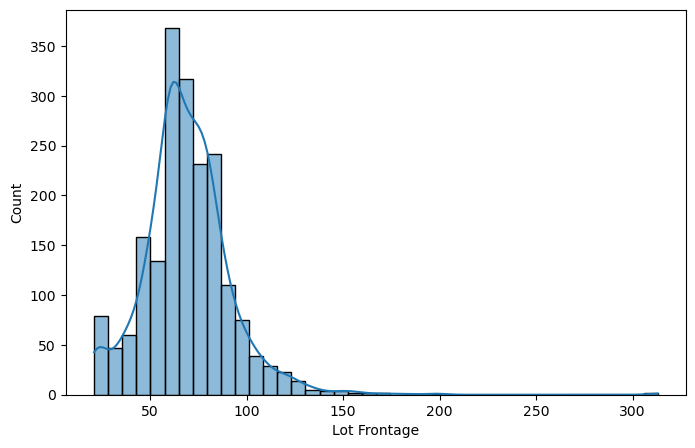

In [78]:

plt.figure(figsize=(8, 5))
sns.histplot(train_df['Lot Frontage'], kde=True, bins=40)
plt.show()

In [79]:
# Hangi değerin kaç kere geçtiği
pd.set_option('display.max_rows', None) 
train_df["Lot Frontage"].value_counts()
# ayarı kapatmak istersen sonra  "pd.set_option('display.max_rows', None)"

Lot Frontage
60.0     222
70.0     111
80.0     110
50.0      92
75.0      81
65.0      75
85.0      57
90.0      39
24.0      39
78.0      38
68.0      38
21.0      36
64.0      35
74.0      31
63.0      29
72.0      27
79.0      26
62.0      26
59.0      24
73.0      23
82.0      23
57.0      22
51.0      22
53.0      22
76.0      21
88.0      21
55.0      21
100.0     21
66.0      21
52.0      20
43.0      18
40.0      18
67.0      17
56.0      17
58.0      16
81.0      16
61.0      16
35.0      15
44.0      14
69.0      14
84.0      14
34.0      14
71.0      14
95.0      13
48.0      13
120.0     13
83.0      12
110.0     12
96.0      12
93.0      12
77.0      12
91.0      11
86.0      10
92.0      10
98.0      10
54.0      10
42.0      10
41.0      10
87.0       9
102.0      9
89.0       8
94.0       8
105.0      8
45.0       8
30.0       8
36.0       7
39.0       6
99.0       6
32.0       6
37.0       6
47.0       6
103.0      5
107.0      5
114.0      5
109.0      4
49.0       4

In [80]:
print("nunique:",train_df["Lot Frontage"].nunique())
train_df["Lot Frontage"].describe()

nunique: 120


count    1951.000000
mean       69.207586
std        23.418018
min        21.000000
25%        58.000000
50%        68.000000
75%        80.000000
max       313.000000
Name: Lot Frontage, dtype: float64

In [81]:
train_df.groupby("Neighborhood")["Lot Frontage"].median()

Neighborhood
Blmngtn    43.0
Blueste    24.0
BrDale     21.0
BrkSide    52.0
ClearCr    80.5
CollgCr    70.0
Crawfor    66.0
Edwards    65.0
Gilbert    63.0
Greens     40.0
GrnHill     NaN
IDOTRR     60.0
Landmrk     NaN
MeadowV    21.0
Mitchel    71.0
NAmes      74.0
NPkVill    24.0
NWAmes     80.0
NoRidge    85.0
NridgHt    90.0
OldTown    60.0
SWISU      60.0
Sawyer     72.0
SawyerW    67.0
Somerst    72.0
StoneBr    59.5
Timber     80.0
Veenker    80.0
Name: Lot Frontage, dtype: float64

In [82]:
# 1) Yapısal yokluklar test veriisndeki nan değerlerine işlem uygulanır train istatistikleriyle maksat veri sızıntısı olmasın.
test_df = X_test

# sütun isimlerindeki boşluğu kaldır
train_df.columns = train_df.columns.str.replace(' ', '')
test_df.columns  = test_df.columns.str.replace(' ', '')

# nanları doldur
for col in cat_none_cols:
    train_df[col] = train_df[col].fillna('None')
    test_df[col]  = test_df[col].fillna('None')

for col in num_zero_cols:
    train_df[col] = train_df[col].fillna(0)
    test_df[col]  = test_df[col].fillna(0)


# 2) LotFrontage: caddeye uzunluğu bir genel medyan al birde komşuya göre mahalleye göre  (train'den öğren)
nbhd_median = train_df.groupby('Neighborhood')['LotFrontage'].median()
global_median = train_df['LotFrontage'].median()

train_df['LotFrontage'] = train_df['LotFrontage'].fillna(
    train_df['Neighborhood'].map(nbhd_median) # burada map neighborhood değişkeninin yerine median değerini kouyor geçiic olarak
).fillna(global_median)

# traine uyguladığımı teste de uyguluyorum.
test_df['LotFrontage'] = test_df['LotFrontage'].fillna(
    test_df['Neighborhood'].map(nbhd_median)      # aynı nbhd_median
).fillna(global_median)

In [83]:
train_df.isnull().sum() # doğrulama başarılı

Order            0
PID              0
MSSubClass       0
MSZoning         0
LotFrontage      0
LotArea          0
Street           0
Alley            0
LotShape         0
LandContour      0
Utilities        0
LotConfig        0
LandSlope        0
Neighborhood     0
Condition1       0
Condition2       0
BldgType         0
HouseStyle       0
OverallQual      0
OverallCond      0
YearBuilt        0
YearRemod/Add    0
RoofStyle        0
RoofMatl         0
Exterior1st      0
Exterior2nd      0
MasVnrType       0
MasVnrArea       0
ExterQual        0
ExterCond        0
Foundation       0
BsmtQual         0
BsmtCond         0
BsmtExposure     0
BsmtFinType1     0
BsmtFinSF1       0
BsmtFinType2     0
BsmtFinSF2       0
BsmtUnfSF        0
TotalBsmtSF      0
Heating          0
HeatingQC        0
CentralAir       0
Electrical       0
1stFlrSF         0
2ndFlrSF         0
LowQualFinSF     0
GrLivArea        0
BsmtFullBath     0
BsmtHalfBath     0
FullBath         0
HalfBath         0
BedroomAbvGr

#### Numerical Variable Analysis (EDA)

In [84]:
analiz_df = train_df.copy()

# Sayısal olmaması gereken / analize girmemesi gereken sütunlar
analiz_df['MSSubClass'] = analiz_df['MSSubClass'].astype(str)   # bu sütun değerleri aslında kategorik fakat sayılarla ifade ediliyor,
                                                                # bunu hesaba katmamak için stringe çeviriyoruz.

dislanacak_columns = ['SalePrice', 'SalePrice_log', 'Id', 'Order', 'PID']   # hangisi varsa (target variable hesaba girmez)
numerical_columns = (analiz_df.select_dtypes(include=np.number)
                     .columns.difference(dislanacak_columns))

print("Sayısal sütun sayısı:", len(numerical_columns))
print(list(numerical_columns))

Sayısal sütun sayısı: 35
['1stFlrSF', '2ndFlrSF', '3SsnPorch', 'BedroomAbvGr', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtFullBath', 'BsmtHalfBath', 'BsmtUnfSF', 'EnclosedPorch', 'Fireplaces', 'FullBath', 'GarageArea', 'GarageCars', 'GarageYrBlt', 'GrLivArea', 'HalfBath', 'KitchenAbvGr', 'LotArea', 'LotFrontage', 'LowQualFinSF', 'MasVnrArea', 'MiscVal', 'MoSold', 'OpenPorchSF', 'OverallCond', 'OverallQual', 'PoolArea', 'ScreenPorch', 'TotRmsAbvGrd', 'TotalBsmtSF', 'WoodDeckSF', 'YearBuilt', 'YearRemod/Add', 'YrSold']


In [85]:
# korelasyon 2 sayının birlikte nasıl hareket ettiği ölçen sayıdır.
# SalePrice çok çarpık ve dağınık ondan ötüür SalePrice_log ile korelasyonlarına bakıyoruz.

corr = analiz_df[numerical_columns].corrwith(analiz_df['SalePrice_log']).sort_values(ascending=False)

print("En yüksek 15 pozitif korelasyon:")
print(corr.head(15))
print("\nEn düşük 5 (negatif) korelasyon:")
print(corr.tail(5))

En yüksek 15 pozitif korelasyon:
OverallQual      0.818006
GrLivArea        0.683083
GarageCars       0.664734
GarageArea       0.636837
TotalBsmtSF      0.606330
YearBuilt        0.598154
1stFlrSF         0.587635
FullBath         0.571634
YearRemod/Add    0.566718
Fireplaces       0.478890
TotRmsAbvGrd     0.472891
MasVnrArea       0.427701
BsmtFinSF1       0.405282
WoodDeckSF       0.333933
GarageYrBlt      0.320168
dtype: float64

En düşük 5 (negatif) korelasyon:
LowQualFinSF    -0.018015
YrSold          -0.035698
OverallCond     -0.052399
KitchenAbvGr    -0.122999
EnclosedPorch   -0.142248
dtype: float64


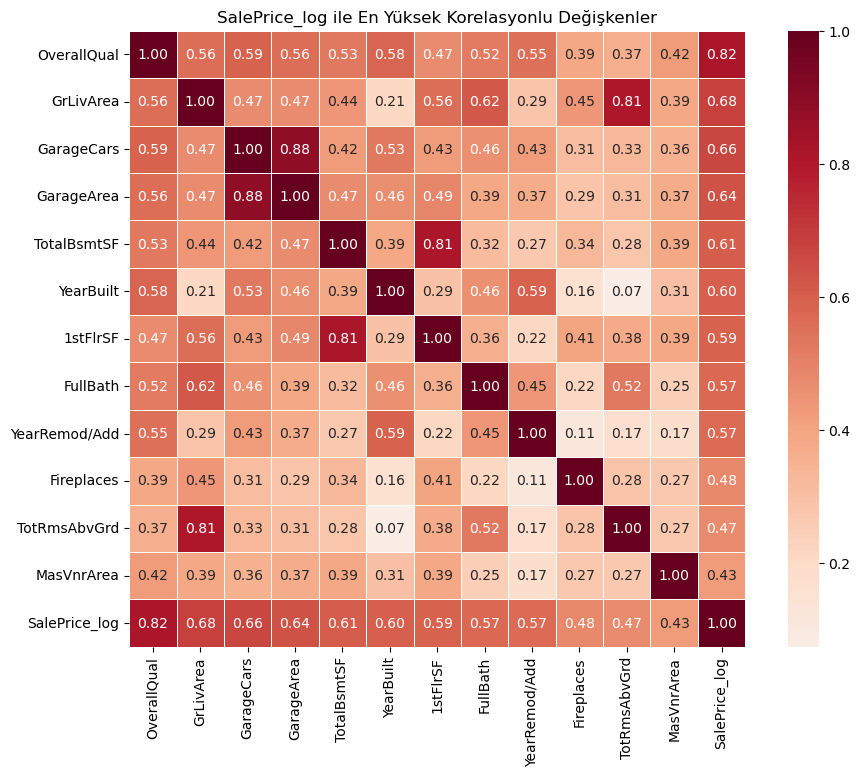

In [86]:
# ısı haritası (heatmap) ile en yüksek korelasyona ship değişkenlerin haritasını grafiğğni çıkarıyoruz.
# abs() yapmamız yani mutlak değer yapmamızın sebebi negatif olan ve yüksek olan bir değerde aslında sonucu çok etkiler.
# coolwarm renk stilini pozitif ve negatifte RdBu_r pozitif ağırlıklı haritlarrda kullan.
# hedef değişken dışında çoklu doğrusallık (multicollinearity) da bakıyoruz bu sayede. örnek GarageCars - GarageArea aynı şeyler aslında.

top_cols = corr.abs().sort_values(ascending=False).head(12).index.tolist()
top_cols.append('SalePrice_log')

plt.figure(figsize=(11, 8))
sns.heatmap(analiz_df[top_cols].corr(), annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, square=True, linewidths=0.5)
plt.title('SalePrice_log ile En Yüksek Korelasyonlu Değişkenler')
plt.show()

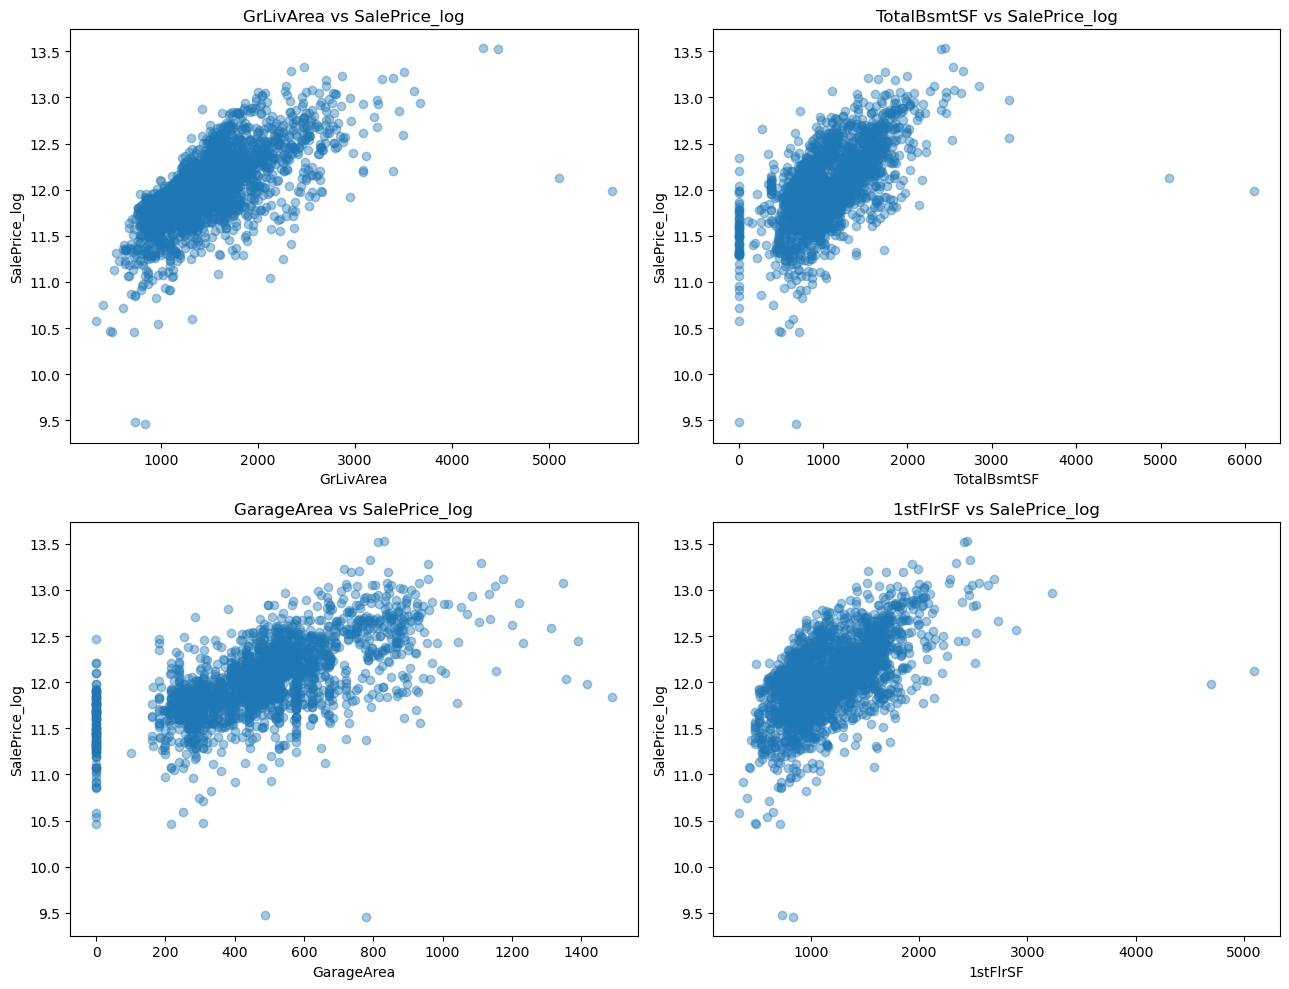

In [87]:
# Sıralı/kategorik (1-10 kalite puanı)
# Sayma (0,1,2,3 araba)
# Yıl (zaman)
# Binary (0/1)
# Bu değerler korelasyon grafiğine gerek kalmaz .
# Korelasyon grafiğine katılması için sürekli değer olması lazım  (m2 ) gibi. onun için yüksek değerli 
# korelasyonlardan sürekli değerlerin "Scatter" grafiklerine bakıyoruz. çok uçta izole noktalar aykırı olabilir.
# ilişkileri saçılım üzerinden daha rahat görebilirz.
# sürekli olmayan yukaırda bahsettiklerimiz "Boxplot" ile bakılır grafiğe

scatter_cols = ['GrLivArea', 'TotalBsmtSF', 'GarageArea', '1stFlrSF']

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, col in zip(axes.ravel(), scatter_cols):
    ax.scatter(analiz_df[col], analiz_df['SalePrice_log'], alpha=0.4)
    ax.set_xlabel(col)
    ax.set_ylabel('SalePrice_log')
    ax.set_title(f'{col} vs SalePrice_log')
plt.tight_layout()
plt.show()

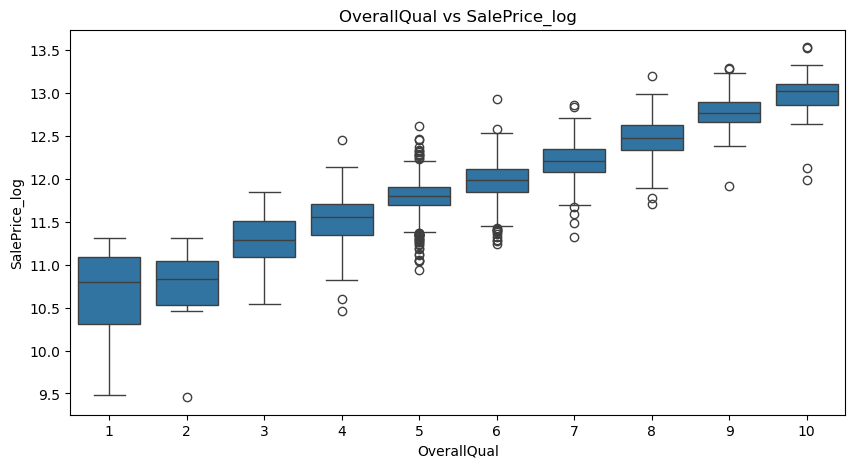

In [88]:
# Ortada ayırna çizgi mediandır %50 yani Q2 ,ortanca değer
# IQR =orta %50 nin yayılımıdır.kısa kutu gruptaki veriler yakın-uzak kutu veriler uzak
#Whisker'ların (kutudan dışarı uzanan iki çizginin) dışındakiler aykırı değerlerdir.daire şeklinde
# Scatter ve Boxplot ta güçlü değerler incelenir.

plt.figure(figsize=(10, 5))
sns.boxplot(x='OverallQual', y='SalePrice_log', data=analiz_df)
plt.title('OverallQual vs SalePrice_log')
plt.show()

In [89]:
# multicollinearity (çoklu doğrusallık) tespiti yapıyoruz 0.7nin üzerindeki eşikleri listeliyoruz. 
# değişkenlerin birbiriyle alakasında çok olanları tespit edip analiz yapıyoruz.
# bu durum modelimize zarar verir.
corr_matrix = analiz_df[numerical_columns].corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

pairs = (upper.stack().reset_index()
              .rename(columns={'level_0': 'Ozellik_1', 'level_1': 'Ozellik_2', 0: 'Korelasyon'}))

yuksek = (pairs[pairs['Korelasyon'] > 0.7]
          .sort_values('Korelasyon', ascending=False)
          .reset_index(drop=True))

print(yuksek)

    Ozellik_1     Ozellik_2  Korelasyon
0  GarageArea    GarageCars    0.884124
1    1stFlrSF   TotalBsmtSF    0.813558
2   GrLivArea  TotRmsAbvGrd    0.806434


In [90]:
#Çarpıklık (Skewness) Kontrolü yapıyoruz.Çok büyük değer gelmesi sebebi orada 0 çok vardır eksik değerde dolduruğumuz.
skew_vals = analiz_df[numerical_columns].skew().sort_values(ascending=False)
print(skew_vals[skew_vals.abs() > 0.75])


#Not :Tüm istatistikler (korelasyon, skew, ortalama, eşikler) sadece train'den hesaplanmalıdır.

MiscVal          20.416138
PoolArea         15.898588
LotArea          13.743796
LowQualFinSF     12.959105
3SsnPorch        12.140302
KitchenAbvGr      4.493078
BsmtFinSF2        4.186328
BsmtHalfBath      4.004087
EnclosedPorch     3.993799
ScreenPorch       3.894896
OpenPorchSF       2.664539
MasVnrArea        2.510566
LotFrontage       1.765874
WoodDeckSF        1.564691
1stFlrSF          1.542293
BsmtFinSF1        1.529875
TotalBsmtSF       1.335827
GrLivArea         1.303483
BsmtUnfSF         0.910189
2ndFlrSF          0.875991
Fireplaces        0.771836
TotRmsAbvGrd      0.767736
GarageYrBlt      -4.014209
dtype: float64


#### Categorical Variable Analysis

In [91]:
# kategorik verilerle analizler için copy yapıyoruz daha sonra numerical olmayan değerleri yani kategorik verileri listeye alıyoruz.
analiz_df = train_df.copy()
analiz_df['MSSubClass'] = analiz_df['MSSubClass'].astype(str)   # kod numarası -> kategorik

dislanacak = ['SalePrice', 'SalePrice_log', 'Id', 'Order', 'PID']
categorical_columns = [c for c in analiz_df.select_dtypes(exclude=np.number).columns if c not in dislanacak]

print("Kategorik sütun sayısı:", len(categorical_columns))
print(categorical_columns)

Kategorik sütun sayısı: 44
['MSSubClass', 'MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


In [92]:
# her sütunda kaç farklı değer olduğunu gösterir
analiz_df[categorical_columns].nunique().sort_values(ascending=False)


Neighborhood     28
MSSubClass       16
Exterior2nd      16
Exterior1st      16
SaleType         10
Condition1        9
Functional        8
Condition2        8
HouseStyle        8
RoofMatl          8
GarageType        7
BsmtFinType2      7
BsmtFinType1      7
MSZoning          7
FireplaceQu       6
Heating           6
Foundation        6
GarageQual        6
GarageCond        6
BsmtCond          6
BsmtQual          6
SaleCondition     6
RoofStyle         6
HeatingQC         5
MiscFeature       5
Fence             5
PoolQC            5
Electrical        5
ExterCond         5
BldgType          5
BsmtExposure      5
MasVnrType        5
LotConfig         5
KitchenQual       4
ExterQual         4
LandContour       4
GarageFinish      4
LotShape          4
LandSlope         3
Utilities         3
Alley             3
PavedDrive        3
CentralAir        2
Street            2
dtype: int64

In [93]:
# sütunlarda bazen neredeyse tek değişkenli oluyorlar onları görmek için 
# çoğunlukla tek değerde toplandığı sütunları görmek için dataframe oluşturduk.
ozet = pd.DataFrame({
    'nunique': analiz_df[categorical_columns].nunique(),
    'best_kategori': analiz_df[categorical_columns].apply(lambda s: s.value_counts().index[0]),
    'best_oran_%': analiz_df[categorical_columns].apply(
        lambda s: s.value_counts(normalize=True).iloc[0] * 100).round(2)
}).sort_values('best_oran_%', ascending=False)

print(ozet[ozet['best_oran_%'] > 80])

               nunique best_kategori  best_oran_%
Utilities            3        AllPub        99.87
Street               2          Pave        99.53
PoolQC               5          None        99.49
Condition2           8          Norm        99.15
Heating              6          GasA        98.34
RoofMatl             8       CompShg        98.29
MiscFeature          5          None        95.99
LandSlope            3           Gtl        95.05
CentralAir           2             Y        93.26
Functional           8           Typ        93.13
Alley                3          None        93.09
Electrical           5         SBrkr        91.47
GarageCond           6            TA        91.04
PavedDrive           3             Y        90.15
LandContour          4           Lvl        89.97
BsmtCond             6            TA        89.68
GarageQual           6            TA        89.29
SaleType            10           WD         87.29
ExterCond            5            TA        86.86


In [94]:
for col in categorical_columns:
    oranlar = analiz_df[col].value_counts(normalize=True)
    nadir = oranlar[oranlar < 0.01]
    if len(nadir) > 0:
        print(f"{col}: {len(nadir)} nadir kategori -> {list(nadir.index)}")

MSSubClass: 5 nadir kategori -> ['75', '180', '45', '40', '150']
MSZoning: 3 nadir kategori -> ['C (all)', 'A (agr)', 'I (all)']
Street: 1 nadir kategori -> ['Grvl']
LotShape: 1 nadir kategori -> ['IR3']
Utilities: 2 nadir kategori -> ['NoSewr', 'NoSeWa']
LotConfig: 1 nadir kategori -> ['FR3']
LandSlope: 1 nadir kategori -> ['Sev']
Neighborhood: 7 nadir kategori -> ['Blmngtn', 'Veenker', 'NPkVill', 'Greens', 'Blueste', 'GrnHill', 'Landmrk']
Condition1: 4 nadir kategori -> ['RRAe', 'PosA', 'RRNn', 'RRNe']
Condition2: 7 nadir kategori -> ['Feedr', 'Artery', 'PosA', 'PosN', 'RRNn', 'RRAe', 'RRAn']
HouseStyle: 3 nadir kategori -> ['2.5Unf', '1.5Unf', '2.5Fin']
RoofStyle: 4 nadir kategori -> ['Gambrel', 'Flat', 'Mansard', 'Shed']
RoofMatl: 7 nadir kategori -> ['Tar&Grv', 'WdShake', 'WdShngl', 'Roll', 'ClyTile', 'Membran', 'Metal']
Exterior1st: 6 nadir kategori -> ['BrkComm', 'Stone', 'AsphShn', 'CBlock', 'PreCast', 'ImStucc']
Exterior2nd: 6 nadir kategori -> ['Brk Cmn', 'ImStucc', 'Stone', 

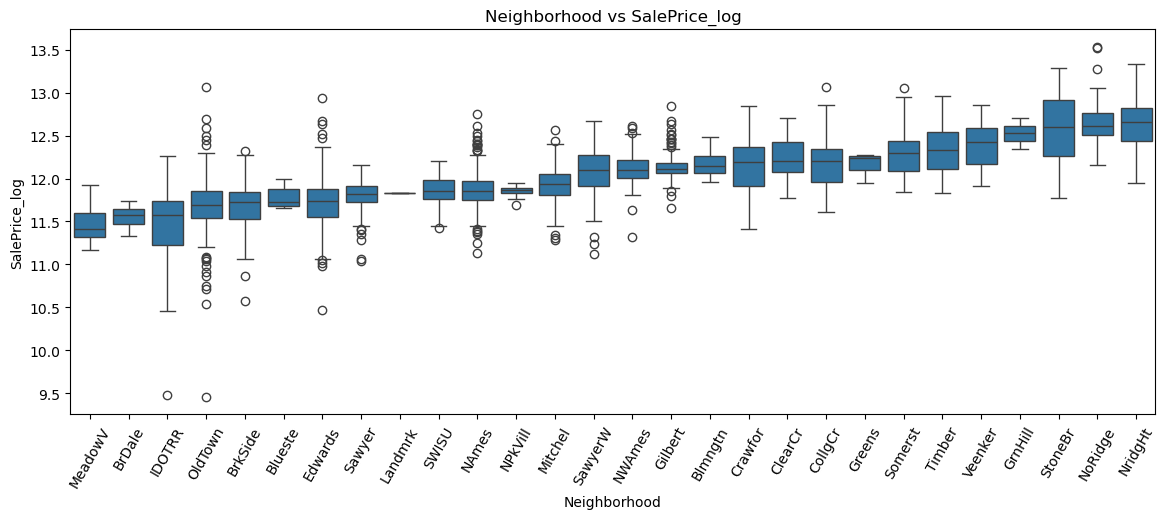

In [95]:
col = 'Neighborhood'
order = analiz_df.groupby(col)['SalePrice_log'].median().sort_values().index

plt.figure(figsize=(14, 5))
sns.boxplot(x=col, y='SalePrice_log', data=analiz_df, order=order)
plt.xticks(rotation=60)
plt.title(f'{col} vs SalePrice_log')
plt.show()

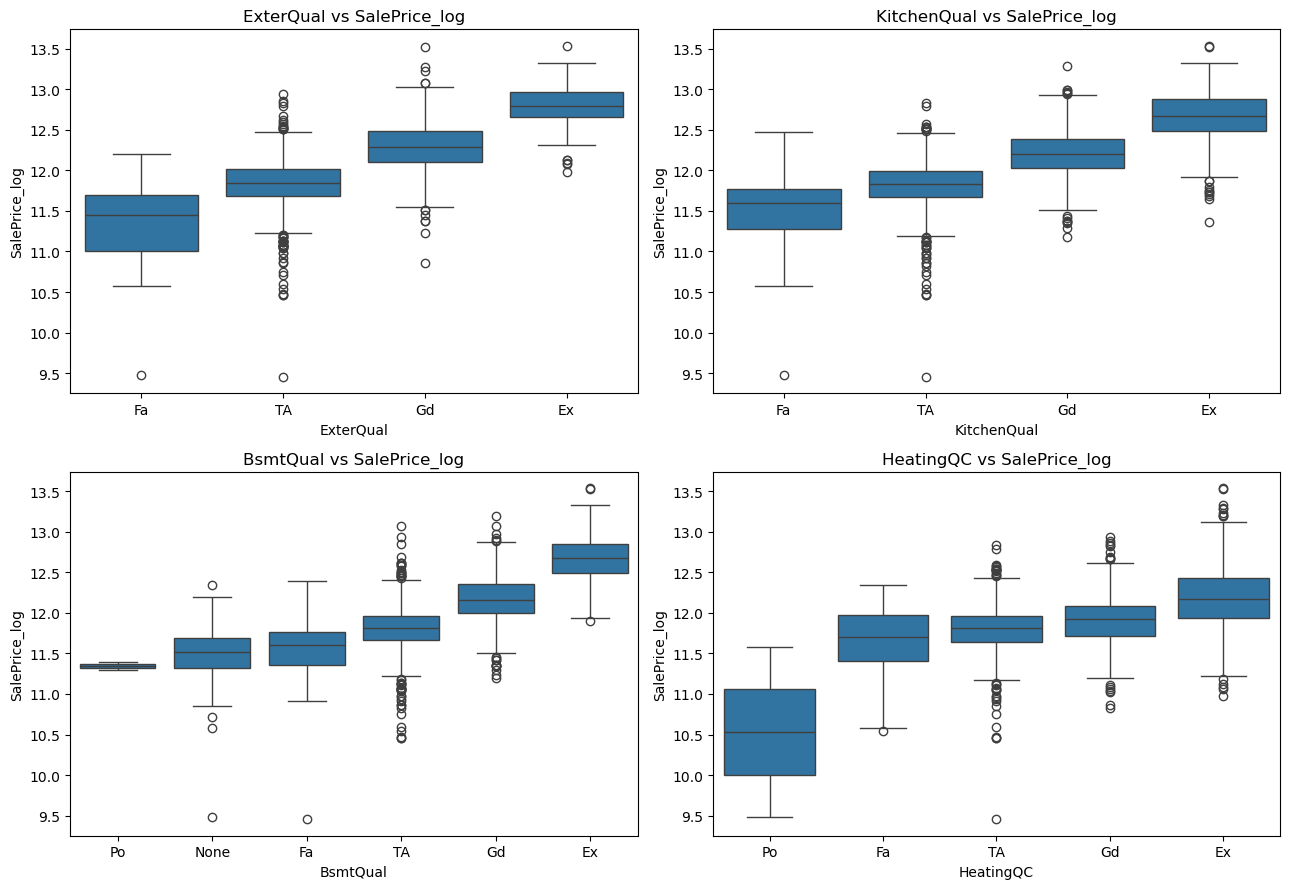

In [96]:
# ordinal sütunları analiz ediyoruz.
# ordinal(sıralı) değerler gerçekten de fiyatı etkiliyor mu?

quality_cols = ['ExterQual', 'KitchenQual', 'BsmtQual', 'HeatingQC']

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.ravel(), quality_cols):
    order = analiz_df.groupby(col)['SalePrice_log'].median().sort_values().index
    sns.boxplot(x=col, y='SalePrice_log', data=analiz_df, order=order, ax=ax)
    ax.set_title(f'{col} vs SalePrice_log')
plt.tight_layout()
plt.show()

In [97]:
# Kategorik sütunlar için korelasyon yerine eta-kare (η²) kullanılır. 
# Bir sütunun hedefteki değişimin yüzde kaçını açıklıyor? sorusuna ceva verir.
# 0.14 üzeri güçlüdür ,0.06-0.14 Orta ,0.01-0.06 Zayıf, 0.01 aşağısı neredeyse ilişkisiz.

def eta_squared(df, col, target='SalePrice_log'):
    genel_ort = df[target].mean()
    ss_between = sum(len(g) * (g.mean() - genel_ort) ** 2
                     for _, g in df.groupby(col)[target])
    ss_total = ((df[target] - genel_ort) ** 2).sum()
    return ss_between / ss_total

eta = pd.Series({c: eta_squared(analiz_df, c) for c in categorical_columns}).sort_values(ascending=False)
print(eta.head(15))
print("\nEn zayıf 10:")
print(eta.tail(10))

Neighborhood    0.563512
BsmtQual        0.469524
ExterQual       0.445640
KitchenQual     0.427638
GarageFinish    0.344974
MSSubClass      0.318340
Foundation      0.310410
GarageType      0.308535
FireplaceQu     0.295048
HeatingQC       0.242998
BsmtFinType1    0.242749
MSZoning        0.192832
Exterior1st     0.180617
MasVnrType      0.168345
BsmtExposure    0.163464
dtype: float64

En zayıf 10:
Alley          0.028433
Heating        0.025062
LotConfig      0.020538
RoofMatl       0.013598
Condition2     0.012820
PoolQC         0.010413
Street         0.008433
MiscFeature    0.004067
LandSlope      0.002791
Utilities      0.002722
dtype: float64


In [98]:
# Encoding aşamasında her kategorik sütuna nasıl davranacağımıza şimdiden karar veriyoruz.
# Sadece plan yapıyoruz,herhangi bir değişiklik yapmadık.
# Kategorik sütunların hepsi aynı değil. Her birine farklı encoding uygulanmalı, yoksa model yanlış öğrenir bundan ötürü ayırmak gerek.

ordinal_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
                'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC',
                'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'GarageFinish',
                'LotShape', 'LandSlope', 'Functional', 'PavedDrive', 'Fence']
binary_cols = ['CentralAir', 'Street']

nominal_cols = [c for c in categorical_columns if c not in ordinal_cols + binary_cols]
print("Ordinal:", len(ordinal_cols), "| Binary:", len(binary_cols), "| Nominal:", len(nominal_cols))
print("Nominal liste:", nominal_cols)

Ordinal: 19 | Binary: 2 | Nominal: 23
Nominal liste: ['MSSubClass', 'MSZoning', 'Alley', 'LandContour', 'Utilities', 'LotConfig', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'Heating', 'Electrical', 'GarageType', 'MiscFeature', 'SaleType', 'SaleCondition']


In [99]:
# "Test'te olup train'de olmayan kategoriler" kümesini buluyor (küme farkı -).
#  Yani sadece test'te görülen, train'de görülmeyen değerler.
# Encodingden önce bir bakıyoruz ,sızıntı yapmıyoruz sadece karşılaştırma.
test_check = test_df.copy()
test_check['MSSubClass'] = test_check['MSSubClass'].astype(str)

for col in categorical_columns:
    gorulmemis = set(test_check[col].unique()) - set(analiz_df[col].unique())
    if gorulmemis:
        print(f"{col}: test'te var, train'de yok -> {gorulmemis}")

Exterior2nd: test'te var, train'de yok -> {'Other'}
Electrical: test'te var, train'de yok -> {nan}
KitchenQual: test'te var, train'de yok -> {'Po'}
MiscFeature: test'te var, train'de yok -> {'TenC'}


#### Outlier Handling Analysis

In [100]:
# hazırlık
analiz_df = train_df.copy()
analiz_df['MSSubClass'] = analiz_df['MSSubClass'].astype(str)

dislanacak = ['SalePrice', 'SalePrice_log', 'Id', 'Order', 'PID']
num_cols = (analiz_df.select_dtypes(include=np.number)
                     .columns.difference(dislanacak))

print("Sayısal sütun sayısı:", len(num_cols))
print("Train satır sayısı:", len(train_df))

Sayısal sütun sayısı: 35
Train satır sayısı: 2344


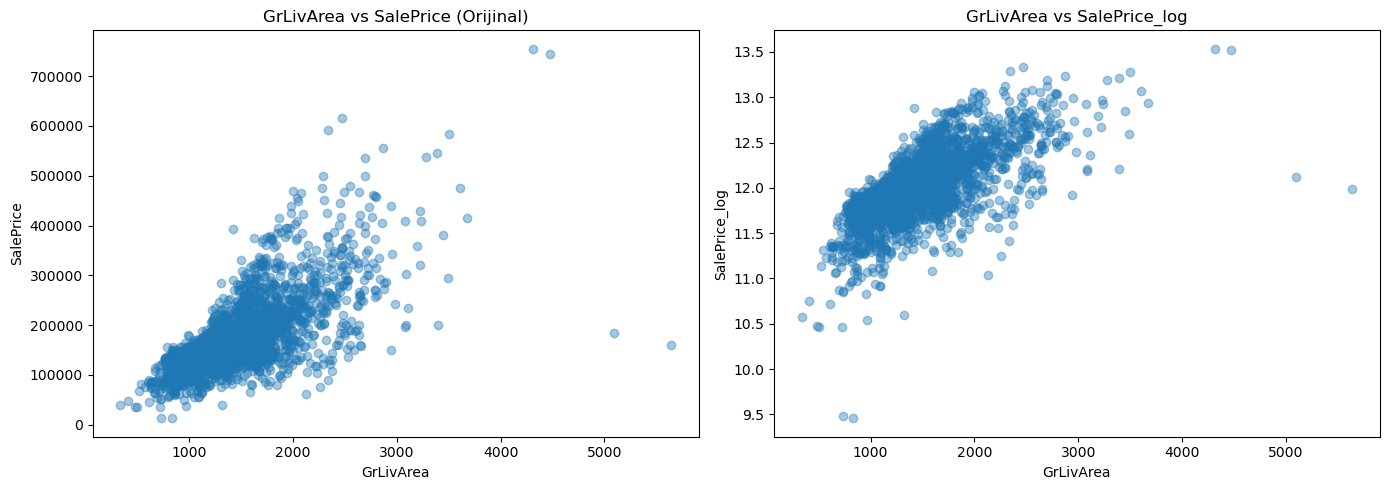

In [101]:
# aykırı değerleri scatte üzerinden görebilmek için hemde orjinal ile
#  log dönüşümlü farkına da baıyoruz hangisinde daha net belli oluyor.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(analiz_df['GrLivArea'], analiz_df['SalePrice'], alpha=0.4)
axes[0].set_xlabel('GrLivArea')
axes[0].set_ylabel('SalePrice')
axes[0].set_title('GrLivArea vs SalePrice (Orijinal)')

axes[1].scatter(analiz_df['GrLivArea'], analiz_df['SalePrice_log'], alpha=0.4)
axes[1].set_xlabel('GrLivArea')
axes[1].set_ylabel('SalePrice_log')
axes[1].set_title('GrLivArea vs SalePrice_log')

plt.tight_layout()
plt.show()

In [102]:
## GrLivArea > 4000 olan evleri listele (4000 eşiği veri seti dokümanından).
# Fiyat filtreye dahil değil; önce tüm büyük evleri gör, sonra karar ver.
# Düşük fiyat + Partial(tamamlanmamış ev) → silme adayı; yüksek fiyat + yüksek kalite → gerçek lüks, bırak.

supheli = analiz_df[(analiz_df['GrLivArea'] > 4000)]

print("GrLivArea > 4000 olan ev sayısı:", len(supheli))
cols_bak = ['GrLivArea', 'SalePrice', 'OverallQual', 'Neighborhood','SaleCondition', 'YearBuilt', 'TotalBsmtSF']
print(supheli[cols_bak])

GrLivArea > 4000 olan ev sayısı: 4
      GrLivArea  SalePrice  OverallQual Neighborhood SaleCondition  YearBuilt  \
1498       5642     160000           10      Edwards       Partial       2008   
1760       4476     745000           10      NoRidge       Abnorml       1996   
1767       4316     755000           10      NoRidge        Normal       1994   
2180       5095     183850           10      Edwards       Partial       2008   

      TotalBsmtSF  
1498       6110.0  
1760       2396.0  
1767       2444.0  
2180       5095.0  


In [103]:
# alt sınır ve üst sınır 0 ise çoğunlukla o özellik o stünda yoktur genelde  ondan ötrüü var olanlar aykırı diye gösterilir.
# Bu tablo silmek için değil, bilgi almak için analiz ediyoruz.
# aksi halde veri kalmaz tüm aykırı değerleri silersek.Aykırı olup gerçek dışıları sileriz elimizden geldiğince.


def iqr_outlier_ozeti(df, cols, k=1.5):
    sonuc = []
    for c in cols:
        q1, q3 = df[c].quantile(0.25), df[c].quantile(0.75)
        iqr = q3 - q1
        alt, ust = q1 - k * iqr, q3 + k * iqr
        n_out = ((df[c] < alt) | (df[c] > ust)).sum()
        sonuc.append({'Sutun': c, 'Alt_Sinir': alt, 'Ust_Sinir': ust,
                      'Outlier_Sayisi': n_out,
                      'Outlier_%': round(n_out / len(df) * 100, 2)})
    return (pd.DataFrame(sonuc)
              .sort_values('Outlier_Sayisi', ascending=False)
              .reset_index(drop=True))

iqr_tablo = iqr_outlier_ozeti(analiz_df, num_cols)
print(iqr_tablo.head(15))

            Sutun  Alt_Sinir  Ust_Sinir  Outlier_Sayisi  Outlier_%
0   EnclosedPorch      0.000      0.000             388      16.55
1      BsmtFinSF2      0.000      0.000             285      12.16
2     ScreenPorch      0.000      0.000             205       8.75
3     OverallCond      3.500      7.500             196       8.36
4      MasVnrArea   -235.500    392.500             163       6.95
5     LotFrontage     30.000    110.000             157       6.70
6    BsmtHalfBath      0.000      0.000             136       5.80
7     OpenPorchSF   -105.000    175.000             124       5.29
8     GarageYrBlt   1892.500   2064.500             123       5.25
9         LotArea   1439.875  17510.875             113       4.82
10   KitchenAbvGr      1.000      1.000             103       4.39
11    TotalBsmtSF     28.000   2044.000              95       4.05
12        MiscVal      0.000      0.000              91       3.88
13      GrLivArea    203.375   2652.375              59       

In [104]:
# Z-score (standart skor), bir değerin ortalamadan kaç standart sapma uzakta olduğunu ifade eden sayıdır.z = (x - ortalama) / std
# genelde |z| > 3 aykırı kabul edilir.
from scipy import stats

z_cols = ['GrLivArea', 'LotArea', 'TotalBsmtSF', 'SalePrice_log']

for c in z_cols:
    z = np.abs(stats.zscore(analiz_df[c]))
    print(f"{c}: |z| > 3 olan satır sayısı = {(z > 3).sum()}")


GrLivArea: |z| > 3 olan satır sayısı = 21
LotArea: |z| > 3 olan satır sayısı = 20
TotalBsmtSF: |z| > 3 olan satır sayısı = 17
SalePrice_log: |z| > 3 olan satır sayısı = 16


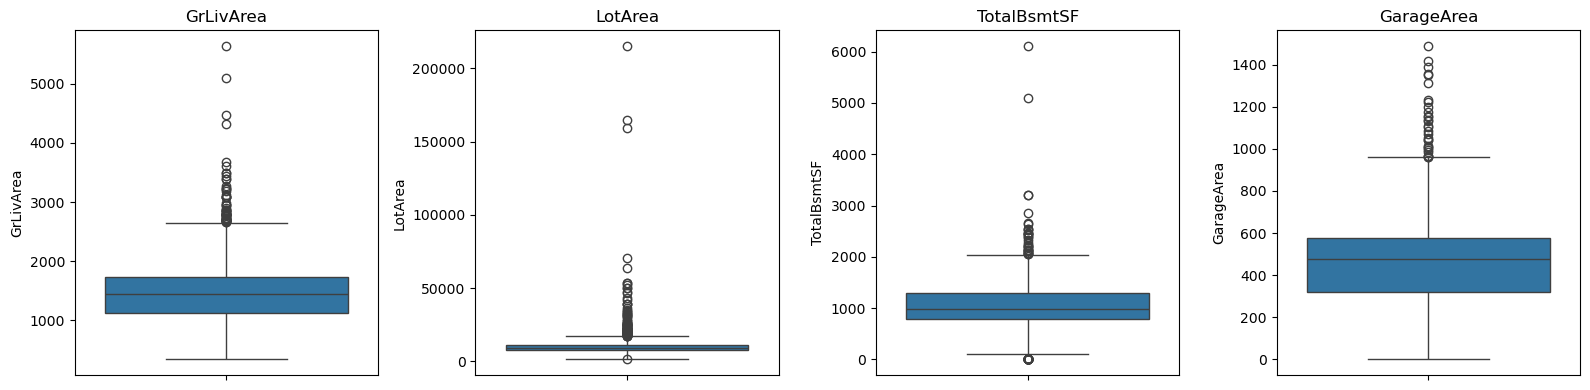

In [105]:
# hangi probleme hangi grafik çözümü
# Tek değişkenin dağılımı nedir?	Histogram / Boxplot / Violin
# Aykırı değer var mı?	Boxplot
# İki değişken arasında ilişki var mı?	Scatter plot
# Kategorik grup × sürekli değer karşılaştırması	Boxplot / Violin (grup bazında)
# Zaman içinde değişim	Line plot

box_cols = ['GrLivArea', 'LotArea', 'TotalBsmtSF', 'GarageArea']

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, box_cols):
    sns.boxplot(y=analiz_df[c], ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

In [ ]:
# Silme ilişkisini belirledik.
print("Silmeden önce:", train_df.shape)
print("Korelasyon (log fiyat ile):",train_df['GrLivArea'].corr(train_df['SalePrice_log']).round(4))

# Büyük alan + düşük fiyat: tutarsız evler
silinecek = train_df[(train_df['GrLivArea'] > 4000) &
                     (train_df['SalePrice'] < 300000)]

print("Silinecek ev sayısı:", len(silinecek))
print(silinecek[['GrLivArea', 'SalePrice', 'SaleCondition']])

Silmeden önce: (2344, 83)
Korelasyon (log fiyat ile): 0.6831
Silinecek ev sayısı: 2
      GrLivArea  SalePrice SaleCondition
1498       5642     160000       Partial
2180       5095     183850       Partial


In [107]:
# Yukarıdaki liste mantıklıysa sil (index etiketine göre)
train_df = train_df.drop(index=silinecek.index)

print("Silmeden sonra:", train_df.shape)

Silmeden sonra: (2342, 83)


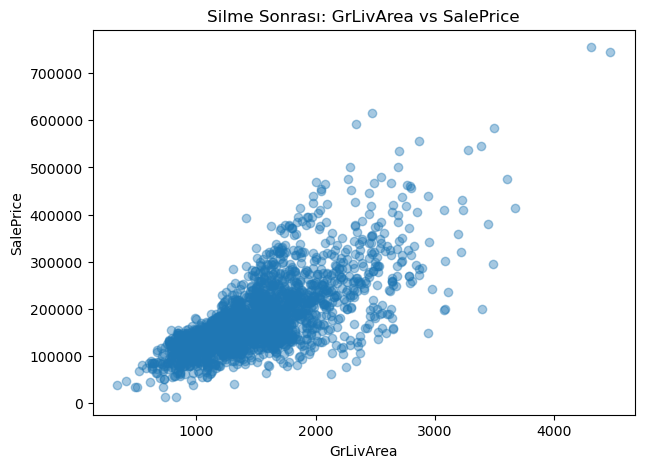

Korelasyon (log fiyat ile): 0.7005


In [109]:
plt.figure(figsize=(7, 5))
plt.scatter(train_df['GrLivArea'], train_df['SalePrice'], alpha=0.4)
plt.xlabel('GrLivArea')
plt.ylabel('SalePrice')
plt.title('Silme Sonrası: GrLivArea vs SalePrice')
plt.show()

print("Korelasyon (log fiyat ile):",train_df['GrLivArea'].corr(train_df['SalePrice_log']).round(4))

# Corelasyon arttı.